In [1]:

from pathlib import Path

PROJECT_DIR = Path("/home/aahana/SANKET_Backend")
DATASET_DIR = Path("/mnt/c/aahana/SANKET/alphabets_and_numbers")

print("Project exists:", PROJECT_DIR.exists())
print("Dataset path exists:", DATASET_DIR.exists())

if DATASET_DIR.exists():
    print("\nDataset contents:")
    for item in sorted(DATASET_DIR.iterdir()):
        print(item.name, "—", "Folder" if item.is_dir() else "File")
else:
    print("\nDataset not found. Check whether the ZIP was extracted.")

Project exists: True
Dataset path exists: True

Dataset contents:
1 — Folder
2 — Folder
3 — Folder
4 — Folder
5 — Folder
6 — Folder
7 — Folder
8 — Folder
9 — Folder
A — Folder
B — Folder
C — Folder
D — Folder
E — Folder
F — Folder
G — Folder
H — Folder
I — Folder
J — Folder
K — Folder
L — Folder
M — Folder
N — Folder
O — Folder
P — Folder
Q — Folder
R — Folder
S — Folder
T — Folder
U — Folder
V — Folder
W — Folder
X — Folder
Y — Folder
Z — Folder


In [ ]:

from pathlib import Path
from PIL import Image
from collections import Counter

class_folders = sorted(
    [p for p in DATASET_DIR.iterdir() if p.is_dir()],
    key=lambda p: p.name
)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_counts = {}
corrupt_images = []
unsupported_files = []

for folder in class_folders:
    files = [p for p in folder.rglob("*") if p.is_file()]
    images = [p for p in files if p.suffix.lower() in image_extensions]

    class_counts[folder.name] = len(images)

    for path in images:
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            corrupt_images.append(str(path))

    unsupported_files.extend(
        str(p) for p in files
        if p.suffix.lower() not in image_extensions
    )

print("Number of classes:", len(class_counts))
print("Total supported images:", sum(class_counts.values()))
print("Corrupt images:", len(corrupt_images))
print("Unsupported files:", len(unsupported_files))
print("\nImages per class:")

for label, count in sorted(class_counts.items()):
    print(f"{label}: {count}")

print("\nMissing expected classes:",
      sorted(set("0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ") - set(class_counts)))


In [3]:

from pathlib import Path
from collections import Counter

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_counts = {}

for folder in sorted(DATASET_DIR.iterdir()):
    if folder.is_dir():
        count = sum(
            1 for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in image_extensions
        )
        class_counts[folder.name] = count

print("Number of classes:", len(class_counts))
print("Total images:", sum(class_counts.values()))

for label, count in sorted(class_counts.items()):
    print(f"{label}: {count}")

expected = set("0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ")
print("Missing classes:", sorted(expected - set(class_counts)))


Number of classes: 35
Total images: 128124
1: 1950
2: 1950
3: 1950
4: 1950
5: 1950
6: 1950
7: 1950
8: 1950
9: 1950
A: 4217
B: 4247
C: 4478
D: 4132
E: 4239
F: 4197
G: 4220
H: 4066
I: 4338
J: 3950
K: 4231
L: 4168
M: 4211
N: 4360
O: 4584
P: 4262
Q: 4204
R: 4326
S: 4807
T: 4372
U: 4112
V: 4187
W: 3941
X: 4316
Y: 4278
Z: 4131
Missing classes: ['0']


In [4]:

import pandas as pd
from sklearn.model_selection import train_test_split
from pathlib import Path

PROJECT_DIR = Path("/home/aahana/SANKET_Backend")
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Build an index from the class folders
records = []

for folder in sorted(DATASET_DIR.iterdir()):
    if folder.is_dir():
        for img in folder.iterdir():
            if img.is_file() and img.suffix.lower() in IMAGE_EXTS:
                records.append({
                    "path": str(img),
                    "label": folder.name
                })

df = pd.DataFrame(records)
print("Indexed images:", len(df))
print("Classes:", df["label"].nunique())

# 70% train, 15% validation, 15% test
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

train_df.to_csv(PROJECT_DIR / "combined_train.csv", index=False)
val_df.to_csv(PROJECT_DIR / "combined_val.csv", index=False)
test_df.to_csv(PROJECT_DIR / "combined_test.csv", index=False)

print("\nTrain:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("\nTrain class counts:")
print(train_df["label"].value_counts().sort_index())
print("\nSaved split CSV files in:", PROJECT_DIR)


Indexed images: 128124
Classes: 35

Train: 89686
Validation: 19219
Test: 19219

Train class counts:
label
1    1365
2    1365
3    1365
4    1365
5    1365
6    1365
7    1365
8    1365
9    1365
A    2952
B    2973
C    3134
D    2892
E    2967
F    2938
G    2954
H    2846
I    3036
J    2765
K    2962
L    2918
M    2948
N    3052
O    3209
P    2983
Q    2943
R    3028
S    3365
T    3060
U    2878
V    2931
W    2759
X    3021
Y    2995
Z    2892
Name: count, dtype: int64

Saved split CSV files in: /home/aahana/SANKET_Backend


In [5]:

import shutil
from pathlib import Path

linux_disk = shutil.disk_usage("/home/aahana")
dataset_disk = shutil.disk_usage(str(DATASET_DIR))

print("Linux home storage:")
print(f"Free: {linux_disk.free / (1024**3):.2f} GB")

print("\nDataset drive storage:")
print(f"Free: {dataset_disk.free / (1024**3):.2f} GB")

print("\nDataset location:", DATASET_DIR)
print("Target location:", PROJECT_DIR / "data" / "combined_dataset")


Linux home storage:
Free: 923.20 GB

Dataset drive storage:
Free: 79.05 GB

Dataset location: /mnt/c/aahana/SANKET/alphabets_and_numbers
Target location: /home/aahana/SANKET_Backend/data/combined_dataset


In [7]:

import shutil
from pathlib import Path

SOURCE_DIR = DATASET_DIR
LOCAL_DATA_DIR = PROJECT_DIR / "data" / "combined_dataset"

if LOCAL_DATA_DIR.exists():
    print("Destination already exists:", LOCAL_DATA_DIR)
    print("Skipping copy to avoid overwriting existing files.")
else:
    LOCAL_DATA_DIR.mkdir(parents=True, exist_ok=True)

    for folder in sorted(SOURCE_DIR.iterdir()):
        if folder.is_dir():
            shutil.copytree(
                folder,
                LOCAL_DATA_DIR / folder.name
            )

    print("Dataset copied successfully!")

print("Local dataset:", LOCAL_DATA_DIR)
print("Class folders:", sum(p.is_dir() for p in LOCAL_DATA_DIR.iterdir()))


Destination already exists: /home/aahana/SANKET_Backend/data/combined_dataset
Skipping copy to avoid overwriting existing files.
Local dataset: /home/aahana/SANKET_Backend/data/combined_dataset
Class folders: 35


In [8]:

from pathlib import Path

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

local_counts = {}

for folder in sorted(LOCAL_DATA_DIR.iterdir()):
    if folder.is_dir():
        local_counts[folder.name] = sum(
            1 for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS
        )

print("Local classes:", len(local_counts))
print("Local images:", sum(local_counts.values()))
print("\nImages per class:")

for label, count in local_counts.items():
    print(f"{label}: {count}")

print("\nMatches original counts:", local_counts == class_counts)


Local classes: 35
Local images: 128124

Images per class:
1: 1950
2: 1950
3: 1950
4: 1950
5: 1950
6: 1950
7: 1950
8: 1950
9: 1950
A: 4217
B: 4247
C: 4478
D: 4132
E: 4239
F: 4197
G: 4220
H: 4066
I: 4338
J: 3950
K: 4231
L: 4168
M: 4211
N: 4360
O: 4584
P: 4262
Q: 4204
R: 4326
S: 4807
T: 4372
U: 4112
V: 4187
W: 3941
X: 4316
Y: 4278
Z: 4131

Matches original counts: True


In [9]:

import pandas as pd
from pathlib import Path

CSV_FILES = {
    "train": PROJECT_DIR / "combined_train.csv",
    "val": PROJECT_DIR / "combined_val.csv",
    "test": PROJECT_DIR / "combined_test.csv"
}

for split, csv_path in CSV_FILES.items():
    df = pd.read_csv(csv_path)

    # Replace the original Windows-mounted dataset root
    df["path"] = df["path"].str.replace(
        str(DATASET_DIR),
        str(LOCAL_DATA_DIR),
        regex=False
    )

    df.to_csv(csv_path, index=False)

    missing = sum(not Path(p).is_file() for p in df["path"])

    print(
        f"{split}: {len(df)} images | "
        f"{df['label'].nunique()} classes | "
        f"missing paths: {missing}"
    )

print("\nUpdated CSV paths successfully.")


train: 89686 images | 35 classes | missing paths: 0
val: 19219 images | 35 classes | missing paths: 0
test: 19219 images | 35 classes | missing paths: 0

Updated CSV paths successfully.


In [10]:

import torch
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from pathlib import Path

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

train_df = pd.read_csv(PROJECT_DIR / "combined_train.csv")
val_df = pd.read_csv(PROJECT_DIR / "combined_val.csv")
test_df = pd.read_csv(PROJECT_DIR / "combined_test.csv")

# Keep a consistent class-to-index mapping across all splits
classes = sorted(train_df["label"].astype(str).unique())
class_to_idx = {label: idx for idx, label in enumerate(classes)}
print("Number of classes:", len(classes))
print("Classes:", classes)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class SignDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with Image.open(row["path"]) as image:
            image = image.convert("RGB")
            image = self.transform(image)
        label = class_to_idx[str(row["label"])]
        return image, label

train_dataset = SignDataset(train_df, train_transform)
val_dataset = SignDataset(val_df, eval_transform)
test_dataset = SignDataset(test_df, eval_transform)

BATCH_SIZE = 32
NUM_WORKERS = 4

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

images, labels = next(iter(train_loader))
print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Image tensor finite:", torch.isfinite(images).all().item())
print("Loaders ready.")


Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Number of classes: 35
Classes: ['1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']

Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])
Image tensor finite: True
Loaders ready.


In [11]:

import torch
import torch.nn as nn
from torchvision import models

# Load pretrained ResNet-18
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Replace classifier for our 35 sign classes
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, len(classes))
model = model.to(DEVICE)

# Training configuration
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler("cuda")

BEST_MODEL_PATH = PROJECT_DIR / "best_resnet18_combined.pth"
LAST_MODEL_PATH = PROJECT_DIR / "last_resnet18_combined.pth"

print("Model:", "ResNet-18")
print("Output classes:", model.fc.out_features)
print("Device:", next(model.parameters()).device)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))
print("Best checkpoint:", BEST_MODEL_PATH)
print("Last checkpoint:", LAST_MODEL_PATH)


Model: ResNet-18
Output classes: 35
Device: cuda:0
Trainable parameters: 11194467
Best checkpoint: /home/aahana/SANKET_Backend/best_resnet18_combined.pth
Last checkpoint: /home/aahana/SANKET_Backend/last_resnet18_combined.pth


In [12]:

import time
import copy
import torch
from tqdm.auto import tqdm

NUM_EPOCHS = 15
PATIENCE = 4

best_val_acc = 0.0
epochs_without_improvement = 0
history = []

for epoch in range(NUM_EPOCHS):
    epoch_start = time.time()

    # -------- Training --------
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]")

    for images, labels_batch in train_bar:
        images = images.to(DEVICE, non_blocking=True)
        labels_batch = labels_batch.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = model(images)
            loss = criterion(outputs, labels_batch)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels_batch.size(0)
        train_loss_sum += loss.item() * batch_size
        train_correct += (outputs.argmax(1) == labels_batch).sum().item()
        train_total += batch_size

        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    # -------- Validation --------
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():
        for images, labels_batch in tqdm(
            val_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]"
        ):
            images = images.to(DEVICE, non_blocking=True)
            labels_batch = labels_batch.to(DEVICE, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = model(images)
                loss = criterion(outputs, labels_batch)

            batch_size = labels_batch.size(0)
            val_loss_sum += loss.item() * batch_size
            val_correct += (outputs.argmax(1) == labels_batch).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    scheduler.step(val_acc)
    elapsed = time.time() - epoch_start

    record = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "seconds": elapsed
    }
    history.append(record)

    print(
        f"\nEpoch {epoch+1}/{NUM_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.2%} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc:.2%} | "
        f"Time: {elapsed/60:.1f} min"
    )

    # Always save the latest model state
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "classes": classes,
        "class_to_idx": class_to_idx,
        "val_acc": val_acc,
        "history": history
    }, LAST_MODEL_PATH)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "classes": classes,
            "class_to_idx": class_to_idx,
            "val_acc": val_acc
        }, BEST_MODEL_PATH)

        print("Saved new best model.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch+1}.")
        break

print("\nTraining finished.")
print(f"Best validation accuracy: {best_val_acc:.2%}")
print("Best model saved at:", BEST_MODEL_PATH)


Epoch 1/15 [Train]:   0%|          | 0/2803 [00:00<?, ?it/s]

Epoch 1/15 [Val]:   0%|          | 0/601 [00:00<?, ?it/s]


Epoch 1/15 | Train loss: 0.0642 | Train acc: 98.80% | Val loss: 0.0104 | Val acc: 99.70% | Time: 4.3 min


Epoch 2/15 [Val]:   0%|          | 0/601 [00:00<?, ?it/s]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



...


Epoch 14/15 | Train loss: 0.0002 | Train acc: 99.99% | Val loss: 0.0025 | Val acc: 99.94% | Time: 4.0 min
Saved new best model.


Epoch 15/15 [Train]:   0%|          | 0/2803 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x71e537f25080>
Traceback (most recent call last):
  File "/home/aahana/ml-gpu/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1704, in __del__
    self._shutdown_workers()
  File "/home/aahana/ml-gpu/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1673, in _shutdown_workers
    if w.is_alive():
       ^^^^^Exception ignored in: ^<function _MultiProcessingDataLoaderIter.__del__ at 0x71e537f25080>^
^Traceback (most recent call last):
^  File "/home/aahana/ml-gpu/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1704, in __del__
^    ^self._shutdown_workers()^

  File "/home/aahana/ml-gpu/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1673, in _shutdown_workers
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
        if w.is_alive():assert self._parent_pid == os.getpid(), 'can only test a child process'

       

Epoch 15/15 [Val]:   0%|          | 0/601 [00:00<?, ?it/s]


Epoch 15/15 | Train loss: 0.0013 | Train acc: 99.97% | Val loss: 0.0032 | Val acc: 99.89% | Time: 4.1 min

Training finished.
Best validation accuracy: 99.94%
Best model saved at: /home/aahana/SANKET_Backend/best_resnet18_combined.pth


In [1]:
import os
import torch

print("Working directory:", os.getcwd())
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Notebook environment check complete.")

Working directory: /home/aahana/SANKET_Backend
PyTorch version: 2.13.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Notebook environment check complete.


In [2]:
from pathlib import Path

project_dir = Path("/home/aahana/SANKET_Backend")
files_to_check = [
    "best_resnet18_combined.pth",
    "last_resnet18_combined.pth"
]

for filename in files_to_check:
    path = project_dir / filename
    print(f"\n{filename}")
    print("Exists:", path.exists())
    if path.exists():
        print("Size:", round(path.stat().st_size / (1024**2), 2), "MB")
    


best_resnet18_combined.pth
Exists: True
Size: 42.78 MB

last_resnet18_combined.pth
Exists: True
Size: 128.24 MB


In [3]:
from pathlib import Path

dataset_dir = Path("/home/aahana/SANKET_Backend/data/combined_dataset")

print("Dataset path:", dataset_dir)
print("Dataset exists:", dataset_dir.exists())

if dataset_dir.exists():
    classes = sorted(p.name for p in dataset_dir.iterdir() if p.is_dir())
    print("Number of class folders:", len(classes))
    print("Class folders:", classes)
    print("Total images:", sum(
        1 for p in dataset_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ))

Dataset path: /home/aahana/SANKET_Backend/data/combined_dataset
Dataset exists: True
Number of class folders: 35
Class folders: ['1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
Total images: 128124


In [4]:
import torch

model_path = "/home/aahana/SANKET_Backend/best_resnet18_combined.pth"

checkpoint = torch.load(
    model_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        print("-", key)

    print("\nTensor information:")
    for key, value in checkpoint.items():
        if isinstance(value, torch.Tensor):
            print(key, "shape:", tuple(value.shape))
        elif isinstance(value, (int, float, str, bool)):
            print(key, "=", value)
        elif isinstance(value, dict):
            print(key, "contains", len(value), "entries")

Checkpoint type: <class 'dict'>

Checkpoint keys:
- epoch
- model_state_dict
- classes
- class_to_idx
- val_acc

Tensor information:
epoch = 14
model_state_dict contains 122 entries
class_to_idx contains 35 entries
val_acc = 0.9994276497216297


In [5]:
print("Saved epoch:", checkpoint["epoch"])
print("Saved validation accuracy:", f'{checkpoint["val_acc"] * 100:.4f}%')

print("\nSaved classes:")
print(checkpoint["classes"])

print("\nFirst 10 class mappings:")
for i, (name, index) in enumerate(checkpoint["class_to_idx"].items()):
    if i == 10:
        break
    print(f"{name} -> {index}")

print("\nModel weight examples:")
for key in list(checkpoint["model_state_dict"].keys())[:10]:
    print(key, tuple(checkpoint["model_state_dict"][key].shape))

Saved epoch: 14
Saved validation accuracy: 99.9428%

Saved classes:
['1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']

First 10 class mappings:
1 -> 0
2 -> 1
3 -> 2
4 -> 3
5 -> 4
6 -> 5
7 -> 6
8 -> 7
9 -> 8
A -> 9

Model weight examples:
conv1.weight (64, 3, 7, 7)
bn1.weight (64,)
bn1.bias (64,)
bn1.running_mean (64,)
bn1.running_var (64,)
bn1.num_batches_tracked ()
layer1.0.conv1.weight (64, 64, 3, 3)
layer1.0.bn1.weight (64,)
layer1.0.bn1.bias (64,)
layer1.0.bn1.running_mean (64,)


In [6]:
import json
from pathlib import Path

project_dir = Path("/home/aahana/SANKET_Backend")

print("Project files related to training and inference:")
for path in sorted(project_dir.iterdir()):
    if path.is_file() and (
        path.suffix.lower() in {".ipynb", ".py", ".json"}
        or "class" in path.name.lower()
        or "transform" in path.name.lower()
    ):
        print(path.name)

Project files related to training and inference:
SANKET_Backend.ipynb


In [7]:
import json
from pathlib import Path

notebook_path = Path("/home/aahana/SANKET_Backend/SANKET_Backend.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

keywords = [
    "transforms.Compose",
    "Resize(",
    "CenterCrop(",
    "Normalize(",
    "RandomHorizontalFlip",
    "ImageFolder",
    "train_transform",
    "val_transform",
    "DataLoader"
]

for i, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))
    if any(word in source for word in keywords):
        print(f"\n{'=' * 20} CELL {i} {'=' * 20}")
        print(source[:3500])


==================== CELL 8 ====================

import torch
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from pathlib import Path

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

train_df = pd.read_csv(PROJECT_DIR / "combined_train.csv")
val_df = pd.read_csv(PROJECT_DIR / "combined_val.csv")
test_df = pd.read_csv(PROJECT_DIR / "combined_test.csv")

# Keep a consistent class-to-index mapping across all splits
classes = sorted(train_df["label"].astype(str).unique())
class_to_idx = {label: idx for idx, label in enumerate(classes)}
print("Number of classes:", len(classes))
print("Classes:", classes)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.4

In [9]:
required_vars = [
    "PROJECT_DIR",
    "train_df",
    "val_df",
    "test_df",
    "classes",
    "class_to_idx",
    "eval_transform",
    "test_dataset",
    "test_loader",
    "model",
    "checkpoint"
]

for name in required_vars:
    print(f"{name}: {'Available' if name in globals() else 'Not available'}")

PROJECT_DIR: Not available
train_df: Not available
val_df: Not available
test_df: Not available
classes: Available
class_to_idx: Not available
eval_transform: Not available
test_dataset: Not available
test_loader: Not available
model: Not available
checkpoint: Available


In [10]:
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

PROJECT_DIR = Path("/home/aahana/SANKET_Backend")

train_csv = PROJECT_DIR / "combined_train.csv"
val_csv = PROJECT_DIR / "combined_val.csv"
test_csv = PROJECT_DIR / "combined_test.csv"

print("CSV files:")
for path in [train_csv, val_csv, test_csv]:
    print(path.name, "exists:", path.exists())

assert all(p.exists() for p in [train_csv, val_csv, test_csv]), \
    "A dataset split CSV is missing. Stop and share the output."

train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)
test_df = pd.read_csv(test_csv)

classes = sorted(train_df["label"].astype(str).unique())
class_to_idx = {label: idx for idx, label in enumerate(classes)}

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class SignDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with Image.open(row["path"]) as image:
            image = self.transform(image.convert("RGB"))
        label = class_to_idx[str(row["label"])]
        return image, label

test_dataset = SignDataset(test_df, eval_transform)
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("\nDataset setup restored.")
print("Classes:", len(classes))
print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))
print("Class mapping matches checkpoint:",
      class_to_idx == checkpoint["class_to_idx"])

CSV files:
combined_train.csv exists: True
combined_val.csv exists: True
combined_test.csv exists: True

Dataset setup restored.
Classes: 35
Test images: 19219
Test batches: 601
Class mapping matches checkpoint: True


In [11]:
import torch
from torchvision import models

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_path = PROJECT_DIR / "best_resnet18_combined.pth"

checkpoint = torch.load(
    model_path,
    map_location="cpu",
    weights_only=False
)

model = models.resnet18(weights=None)
model.fc = torch.nn.Linear(model.fc.in_features, len(classes))

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
model.eval()

print("Model loaded successfully.")
print("Device:", DEVICE)
print("Architecture: ResNet-18")
print("Output classes:", model.fc.out_features)
print("Checkpoint validation accuracy:",
      f'{checkpoint["val_acc"] * 100:.4f}%')
print("Model in evaluation mode:", not model.training)

Model loaded successfully.
Device: cuda
Architecture: ResNet-18
Output classes: 35
Checkpoint validation accuracy: 99.9428%
Model in evaluation mode: True


In [12]:
import torch
from tqdm.auto import tqdm

model.eval()
correct = 0
total = 0
class_correct = torch.zeros(len(classes), dtype=torch.long)
class_total = torch.zeros(len(classes), dtype=torch.long)

with torch.inference_mode():
    for images, labels in tqdm(test_loader, desc="Testing"):
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        labels_cpu = labels.cpu()
        predictions_cpu = predictions.cpu()

        for i in range(len(labels_cpu)):
            class_total[labels_cpu[i]] += 1
            if predictions_cpu[i] == labels_cpu[i]:
                class_correct[labels_cpu[i]] += 1

test_accuracy = 100 * correct / total

print(f"\nTest images evaluated: {total}")
print(f"Correct predictions: {correct}")
print(f"Incorrect predictions: {total - correct}")
print(f"Test accuracy: {test_accuracy:.4f}%")

Testing:   0%|          | 0/601 [00:00<?, ?it/s]


Test images evaluated: 19219
Correct predictions: 19208
Incorrect predictions: 11
Test accuracy: 99.9428%


Image path: /home/aahana/SANKET_Backend/data/combined_dataset/Q/Image_1679049485.953827.jpg
Actual label: Q
Predicted label: Q
Confidence: 100.00%
Correct prediction: True


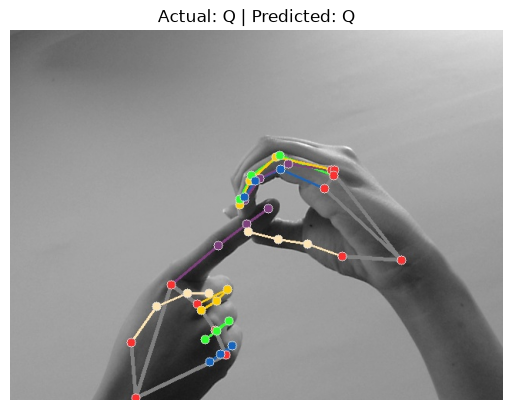

In [13]:
import matplotlib.pyplot as plt
from PIL import Image
import torch

# Select the first image from the test dataset
sample = test_df.iloc[0]
image_path = sample["path"]
actual_label = str(sample["label"])

# Apply the same preprocessing used during evaluation
with Image.open(image_path) as img:
    image = img.convert("RGB")
    input_tensor = eval_transform(image).unsqueeze(0)

# Predict
model.eval()
with torch.inference_mode():
    output = model(input_tensor.to(DEVICE))
    probabilities = torch.softmax(output, dim=1)
    confidence, predicted_idx = probabilities.max(dim=1)

predicted_label = classes[predicted_idx.item()]

print("Image path:", image_path)
print("Actual label:", actual_label)
print("Predicted label:", predicted_label)
print(f"Confidence: {confidence.item() * 100:.2f}%")
print("Correct prediction:", predicted_label == actual_label)

plt.imshow(image)
plt.title(f"Actual: {actual_label} | Predicted: {predicted_label}")
plt.axis("off")
plt.show()

In [27]:

from pathlib import Path
import torch

model_path = Path("/home/aahana/SANKET_Backend/best_resnet18_combined.pth")

print("Checkpoint exists:", model_path.exists())

if model_path.exists():
    checkpoint = torch.load(model_path, map_location="cpu", weights_only=True)
    print("File size:", round(model_path.stat().st_size / (1024**2), 2), "MB")
    print("Saved epoch:", checkpoint.get("epoch"))
    print("Validation accuracy:", checkpoint.get("val_acc"))
    print("Number of classes:", len(checkpoint["classes"]))
    print("Classes:", checkpoint["classes"])
    print("Classifier output shape:", checkpoint["model_state_dict"]["fc.weight"].shape)
else:
    print("Checkpoint not found. Do not change any files yet.")


Checkpoint exists: True
File size: 42.78 MB
Saved epoch: 14
Validation accuracy: 0.9994276497216297
Number of classes: 35
Classes: ['1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
Classifier output shape: torch.Size([35, 512])


In [28]:

from pathlib import Path
from PIL import Image
from torchvision import transforms
import torch

image_path = Path(
    "/home/aahana/SANKET_Backend/data/combined_dataset/Q/Image_1679049485.953827.jpg"
)

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Test image exists:", image_path.exists())

if image_path.exists():
    image = Image.open(image_path).convert("RGB")
    tensor = preprocess(image).unsqueeze(0)
    print("Input shape:", tuple(tensor.shape))
    print("Data type:", tensor.dtype)
    print("All values finite:", torch.isfinite(tensor).all().item())
    print("Preprocessing test:", "PASS" if tensor.shape == (1, 3, 224, 224) and torch.isfinite(tensor).all() else "FAIL")


Test image exists: True
Input shape: (1, 3, 224, 224)
Data type: torch.float32
All values finite: True
Preprocessing test: PASS


In [29]:
import torch
import torch.nn as nn
from torchvision import models
from PIL import Image
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint_path = "/home/aahana/SANKET_Backend/best_resnet18_combined.pth"
image_path = "/home/aahana/SANKET_Backend/data/combined_dataset/Q/Image_1679049485.953827.jpg"

checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
classes = checkpoint["classes"]

model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

image = Image.open(image_path).convert("RGB")
input_tensor = preprocess(image).unsqueeze(0).to(device)

with torch.inference_mode():
    outputs = model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    confidence, predicted_index = probabilities.max(dim=1)

predicted_sign = classes[predicted_index.item()]
confidence = confidence.item()

print("Device:", device)
print("Expected sign: Q")
print("Predicted sign:", predicted_sign)
print(f"Confidence: {confidence:.4%}")
print("Inference test:", "PASS" if predicted_sign == "Q" else "CHECK")

Device: cuda
Expected sign: Q
Predicted sign: Q
Confidence: 99.9999%
Inference test: PASS


In [30]:
try:
    import mediapipe as mp
    print("MediaPipe version:", mp.__version__)
    print("Hand detection availability:", hasattr(mp, "solutions"))
    print("Stage 4:", "PASS" if hasattr(mp, "solutions") else "CHECK")
except ImportError:
    print("MediaPipe is not installed in this notebook's Python environment.")

MediaPipe is not installed in this notebook's Python environment.


In [31]:
%pip install mediapipe

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.5/41.5 MB 1.5 MB/s  0:00:28m0:00:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 MB 1.4 MB/s  0:00:55m0:00:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [mediapipe]/3 [mediapipe]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [32]:
import mediapipe as mp

print("MediaPipe version:", mp.__version__)
print("Hand detection available:", hasattr(mp, "solutions"))

I0000 00:00:1792698910.686578     611 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792698912.025189     611 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792698918.201648     611 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


MediaPipe version: 1.1.1
Hand detection available: False


In [33]:
import mediapipe as mp

print("Version:", mp.__version__)
print("Package location:", mp.__file__)
print("Has solutions:", hasattr(mp, "solutions"))
print("Has tasks:", hasattr(mp, "tasks"))
print("Available hand-related names:",
      [name for name in dir(mp) if "hand" in name.lower()])

Version: 1.1.1
Package location: /home/aahana/ml-gpu/lib/python3.12/site-packages/mediapipe/__init__.py
Has solutions: False
Has tasks: True
Available hand-related names: []


In [34]:
import mediapipe as mp

print("HandLandmarker available:",
      hasattr(mp.tasks.vision, "HandLandmarker"))
print("BaseOptions available:",
      hasattr(mp.tasks, "BaseOptions"))
print("RunningMode available:",
      hasattr(mp.tasks.vision, "RunningMode"))

HandLandmarker available: True
BaseOptions available: True
RunningMode available: True


In [35]:
from pathlib import Path
import urllib.request

model_dir = Path("/home/aahana/SANKET_Backend/models")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "hand_landmarker.task"
model_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "hand_landmarker/hand_landmarker/float16/1/"
    "hand_landmarker.task"
)

if not model_path.exists():
    urllib.request.urlretrieve(model_url, model_path)

print("Model exists:", model_path.exists())
if model_path.exists():
    print("Model size:", round(model_path.stat().st_size / (1024 * 1024), 2), "MB")
    print("Stage 4D:", "PASS" if model_path.stat().st_size > 100_000 else "CHECK")

Model exists: True
Model size: 7.46 MB
Stage 4D: PASS


In [37]:
import mediapipe as mp
from pathlib import Path

model_path = "/home/aahana/SANKET_Backend/models/hand_landmarker.task"

BaseOptions = mp.tasks.BaseOptions
HandLandmarker = mp.tasks.vision.HandLandmarker
HandLandmarkerOptions = mp.tasks.vision.HandLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options = HandLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=model_path),
    running_mode=VisionRunningMode.IMAGE,
    num_hands=1
)

with HandLandmarker.create_from_options(options) as landmarker:
    print("Hand detector initialized successfully.")

print("Stage 4E: PASS")

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792699427.628885    2534 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792699427.665865    2535 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Hand detector initialized successfully.
Stage 4E: PASS


In [38]:
import numpy as np
import mediapipe as mp
from PIL import Image

image_path = "/home/aahana/SANKET_Backend/data/combined_dataset/Q/Image_1679049485.953827.jpg"
model_path = "/home/aahana/SANKET_Backend/models/hand_landmarker.task"

image = Image.open(image_path).convert("RGB")
image_np = np.array(image)

mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_np
)

options = mp.tasks.vision.HandLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(
        model_asset_path=model_path
    ),
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_hands=1
)

with mp.tasks.vision.HandLandmarker.create_from_options(options) as detector:
    result = detector.detect(mp_image)

print("Hands detected:", len(result.hand_landmarks))
print("Detection test:", "PASS" if result.hand_landmarks else "NO HAND DETECTED")

W0000 00:00:1792699465.640922    2572 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792699465.668484    2572 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792699465.693038    2574 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


Hands detected: 0
Detection test: NO HAND DETECTED
